In [2]:
!pip install -q unsloth

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.8/85.8 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 56.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 42.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.1/135.1 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 36.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 58.7 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 59.4 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 217.3/217.3 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 59.6 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 9.1 MB/s eta 0:00:00
ERROR: pi

In [3]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # less GPU-memory fragmentation
import unsloth                     # FIRST, before transformers / trl (it patches them)
import sys, torch, time, json, glob, re, random, gc, tarfile, traceback, math, collections
import pandas as pd, numpy as np
from PIL import Image
print("unsloth", unsloth.__version__, "| torch", torch.__version__, "| GPU", torch.cuda.get_device_name(0))

N_TRAIN, N_DEV = 15000, 500        # same pool as notebook A (14,508 usable clips)
P_DROP = 0.25                      # cue dropout: each cue is removed 25 % of the time during fine-tuning
WHY_GETS_ZOOMS = True              # why/decision questions also get the zoom crops (decided by the judge probe)
TRAIN_DEADLINE_H = 9.0             # stop fine-tuning here so testing + scoring fit in Kaggle's 12 h

T0 = time.time()
INPUT, WORK = "/kaggle/input", "/kaggle/working"
MODE = "cues"
OUT = f"{WORK}/ft_{MODE}"; os.makedirs(OUT, exist_ok=True)
def hours(): return (time.time() - T0) / 3600
_log = open(f"{OUT}/log.txt", "a")
def log(*a):
    s = f"[{hours():5.2f}h] " + " ".join(str(x) for x in a); print(s, flush=True); _log.write(s + "\n"); _log.flush()

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu128, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
unsloth 2026.11.4 | torch 2.11.0+cu128 | GPU Tesla T4


In [13]:
# ---- fixed paths (no slow recursive search). Your dataset: /kaggle/input/datasets/hamsaa123/lingoqa
ROOT = "/kaggle/input/datasets/hamsaa123/lingoqa"
assert os.path.isdir(ROOT), f"not found: {ROOT}  (run:  !ls /kaggle/input/datasets/hamsaa123  to see the real name)"

def split_dir(s):                                     # frames live in ROOT/<split>/<split>/<clip>/0..4.jpg
    d = f"{ROOT}/{s}/{s}"; return d if os.path.isdir(d) else f"{ROOT}/{s}"

def find_parquet(s):                                  # look only in a few likely places, never inside the image folders
    for p in [f"{ROOT}/{s}.parquet", f"{ROOT}/{s}/{s}.parquet", f"{ROOT}/{s}/{s}/{s}.parquet", f"{ROOT}/data/{s}.parquet"]:
        if os.path.exists(p): return p
    for name in os.listdir(ROOT):                     # one level of sub-folders, still fast
        p = f"{ROOT}/{name}/{s}.parquet"
        if os.path.exists(p): return p
    raise FileNotFoundError(f"{s}.parquet not found near {ROOT}  (run:  !ls {ROOT}  and tell me what it prints)")

def load(s):
    t = pd.read_parquet(find_parquet(s)); t["question_id"] = t["question_id"].astype(str); return t

DIRS = {"evaluation": split_dir("evaluation"), "action": split_dir("action"), "scenery": split_dir("scenery")}
for k, v in DIRS.items(): print(k, "frames in:", v, "| exists:", os.path.isdir(v))
ev, ac = load("evaluation"), load("action")
try: sc = load("scenery")
except Exception as e: sc = ac.iloc[:0].copy(); print("no scenery split:", e)
print("rows: evaluation", len(ev), "| action", len(ac), "| scenery", len(sc))
# ---- question tagger (frozen rules). It decides WHICH cues a question is allowed to get: tag(q)["cues"]
NAMES = {1: "why", 2: "decision", 3: "own_action", 4: "hazard", 5: "layout", 6: "counting", 7: "light_state",
         8: "presence", 9: "where", 10: "others_motion", 11: "identity", 12: "scene_other"}
BASE_CUES = {1: ["EGO_DETAIL", "MOVERS"], 2: ["EGO_DETAIL", "MOVERS"], 3: ["EGO_DETAIL"], 4: ["MOVERS"], 5: [], 6: [],
             7: ["LIGHT_ZOOM"], 8: ["FAR_ZOOM"], 9: [], 10: ["MOVERS"], 11: ["FAR_ZOOM"], 12: []}
NO_FLAG_CUES = {5, 6, 9, 12}

def R(p): return re.compile(p, re.I)
LIGHT = R(r"\btraffic[- ]?(?:lights?|signals?)\b|(?<!brake )(?<!tail )(?<!hazard )(?<!street )(?<!indicator )\blights? (?:is|are|ahead|showing|display\w*|colou?r)\b|\bcolou?r of the lights?\b|\b(?:red|green|amber|yellow) lights?\b")
FAR = R(r"\bsigns?\b|\bspeed limit\b|\bpedestrians?\b|\bcyclists?\b|\bbicycles?\b|\bmotorcycl\w*\b|\bmotorbikes?\b|\bscooters?\b|\bpeople\b")
AGENT = r"(?:pedestrians?|cyclists?|bicycles?|bikes?|motorcycl\w*|motorbikes?|scooters?|cars?|vehicles?|vans?|trucks?|lorry|lorries|bus|buses|taxis?|people|person|riders?|minivans?|sedans?|suvs?|traffic(?! signs?| lights?| signals?| islands?))"
EGO = r"(?:you|we|i|the ego(?: car| vehicle)?|the driver|your car|this car)"

COUNT = R(r"\bhow many\b|\bnumber of\b|\bcount\b")
WHY = R(r"^\s*why\b|\breasons?\b|\bjustif\w*|\bwhat (?:is|was|are) causing\b|\bwhat makes\b|\bwhat caused\b|"
        r"\bhow (?:is|are|does|do) (?:the |a |an )?[\w -]{1,40}? (?:impact\w*|affect\w*|influenc\w*) (?:your|our|the ego)|"
        r"\band why\b|\bexplain\b|\bpurpose of\b|\bin anticipation of\b|\banticipating (?:and|while|by)\b|\badjusting your position\b")
HAZARD = R(r"\bhazards?\b|\bdangers?\b|\bdangerous\b|\brisks?\b|\bpay(?:ing)? attention\b|\battention\b|\bfocus\w*\b|"
           r"\bbe aware\b|\baware of\b|\bwatch(?:ing)? (?:out )?for\b|\bobstacles?\b|\bkeep(?:ing)? an eye\b|\bcautious\b")
DECISION = R(rf"\bshould {EGO}\b|\bis it safe\b|\b(?:can|could) {EGO}\b(?! (?:see|spot|notice|observe|identify|tell|describe))|\bare you (?:permitted|allowed|able)\b|\bmust {EGO}\b|"
             rf"\bdo {EGO} (?:need|have) to\b|\bnecessary\b|\brecommended\b|\bhow should\b|\bbest (?:course of )?action\b|"
             rf"\bcourse of action\b|\bwhat should\b|\bwhat would\b|\bwere to\b|\bwhat if\b|\bis it (?:okay|ok|legal|possible|appropriate)\b|"
             rf"\b(?:road|way|path|lane) clear for\b|\bsafe to\b|\bwould it be\b|\b(?:might |may |will )?(?:have|need) to (?:stop|slow|brake|yield|give way|wait)\b")
OWN = R(rf"\bwhat (?:are|is) {EGO} (?:currently |presently |now )?doing\b|\b(?:current|your|driving|ego(?:'s)?) (?:driving )?actions?\b|"
        rf"\bwhat actions? (?:are|is) {EGO}\b|\b(?:are|is) {EGO} (?:currently |presently )?(?:accelerat|decelerat|slow|stop|start|turn|"
        rf"maintain|brak|mov|driv|overtak|chang|remain|wait|follow|steer|speed)\w*|\bwhat (?:are|is) {EGO} (?:currently )?(?:planning|about) to\b|"
        rf"\bwhat manoeuv\w+|\bwhat maneuver\w*|\bhow (?:are|is) {EGO} (?:driving|moving|positioned)\b|\bwhat (?:is|are) {EGO} up to\b")
OTHERS = R(rf"\bwhich (?:way|direction) (?:is|are) (?:the |a |that |this )?(?:\w+ )?{AGENT}\b|\bwhat (?:is|are) (?:the |a |that |this )?(?:\w+ ){{0,3}}{AGENT} "
           rf"(?:\w+ ){{0,3}}doing\b|\b(?:is|are) (?:the |a |any |that |this )?(?:\w+ ){{0,2}}{AGENT} (?:\w+ ){{0,3}}(?:moving|turning|crossing|stopping|"
           rf"braking|indicating|signalling|signaling|overtaking|reversing|waiting|approaching|pulling|merging|slowing|accelerating|changing|coming|going|about to)\b|"
           rf"\bwhat (?:will|is|are) (?:the |a |that )?(?:\w+ ){{0,2}}{AGENT} (?:\w+ ){{0,2}}(?:do next|going to do|about to do|likely to do)\b|"
           rf"\bwhere (?:is|are) (?:the |a |that )?(?:\w+ ){{0,2}}{AGENT} (?:going|heading|headed|turning)\b|\banticipating from\b|"
           rf"\bwhat (?:is|are) the (?:state|status|behaviou?r|activity) of (?:the |a )?(?:\w+ ){{0,3}}{AGENT}\b")
WHERE = R(r"^\s*where\b|\bwhere (?:is|are|can|do|does)\b|\bwhich (?:lane|side)\b|\b(?:on|from|to) which side\b|\bin which (?:lane|direction|position)\b|"
          r"\bleft or (?:the )?right\b|\bposition of\b|\blocation of\b|\bhow far\b|\bwhich direction (?:is|are) (?:the |a )?(?:[\w ]+ )?(?:located|positioned)\b")
LAYOUT = R(r"\bzebra\b|\b(?:pedestrian|zebra|pelican|level|toucan) crossings?\b(?! (?:the|your|our|this|that|in|on|at|from)\b)|\bcrossings? (?:ahead|nearby|here)\b|"
           r"\b(?:cycle|bike|bus|bicycle|turning|left|right|middle|adjacent|oncoming|same) lanes?\b|\b(?:road |lane )?markings?\b|\b(?:type|kind|width) of (?:the )?lane\b|"
           r"\bbox junction\b|\bjunctions?\b|\bintersections?\b|\broundabouts?\b|\bspeed limit\b|\b(?:road |traffic |street |give[- ]way |stop |warning )?signs?\b|"
           r"\broad ?works?\b|\bbus stops?\b|\bkerbs?\b|\bcurbs?\b|\bpavements?\b|\bone[- ]way\b|\bdouble (?:yellow|white)\b|\b(?:yellow|white) lines?\b|"
           r"\btype of road\b|\bkind of road\b|\broad (?:layout|type|surface)\b|\bislands?\b|\bbollards?\b|\bspeed bumps?\b|\bparking (?:bays?|spaces?)\b")
IDENT = R(r"\bwhat (?:kinds?|types?|sorts?|make|model|colou?rs?|brand)\b|\bwhat'?s the colou?r\b|\bcolou?r of\b|\bwhat (?:vehicles?|objects?)\b|\bwhich (?:vehicles?|objects?|car)\b|"
          r"\bwhat (?:is|are) the (?:vehicles?|objects?|cars?|trucks?|bus)\b|\bidentify\b|\bwhat (?:is|are) (?:directly )?(?:in front|ahead|behind)\b|"
          r"\bwhat (?:is|does) (?:it|that|this) (?:say|read|show)\b|\bwhat (?:is|are) written\b")
PRESENCE = R(rf"^\s*(?:is|are) there\b|^\s*(?:do|can|could) you (?:see|spot|notice|observe)\b|\bany {AGENT}\b|\bis there (?:a|an|any)\b|\bare there any\b|"
             rf"\bis anyone\b|\bis anything\b|\bpresence of\b|\b(?:is|are) (?:the |any )?{AGENT} (?:present|visible|around|nearby|ahead|behind|in front)\b")
LIGHT_STATE = R(r"\bcolou?r\b|\bshow\w*\b|\bindicat\w*\b|\bdisplay\w*\b|\bstate\b|\bstatus\b|\b(?:is|are) (?:the |any )?(?:traffic )?(?:lights?|signals?)\b|"
                r"\bwhat (?:do|does|is|are) the (?:traffic )?(?:lights?|signals?)\b|\bis there (?:a|any) (?:traffic )?(?:lights?|signals?)\b|\bare there (?:any )?(?:traffic )?(?:lights?|signals?)\b|"
                r"\b(?:red|green|amber|yellow)\b")

WHERE_GOING = R(rf"\bwhere (?:is|are) (?:the |a |that )?(?:\w+ ){{0,2}}{AGENT} (?:going|heading|headed|turning)\b")
IDENT_STRONG = R(r"^\s*what (?:kinds?|types?|sorts?|make|model|colou?rs?|brand)\b|^\s*what'?s the colou?r\b|^\s*what (?:is|are) the colou?rs? of\b|^\s*which (?:vehicles?|objects?)\b|^\s*what (?:vehicles?|objects?)\b")

REACT = R(rf"\bhow (?:does|do|did|is|are) {EGO} (?:react\w*|respond\w*|behav\w*)")

def tag(q):
    q = " ".join(str(q).split())
    light, far = bool(LIGHT.search(q)), bool(FAR.search(q))
    if COUNT.search(q): c = 6
    elif re.match(r"\s*how should\b", q, re.I): c = 2
    elif REACT.search(q): c = 3
    elif HAZARD.search(q): c = 4
    elif WHY.search(q): c = 1
    elif DECISION.search(q): c = 2
    elif light and LIGHT_STATE.search(q): c = 7
    elif WHERE_GOING.search(q): c = 10
    elif WHERE.search(q): c = 9
    elif IDENT_STRONG.search(q): c = 11
    elif OTHERS.search(q): c = 10
    elif OWN.search(q): c = 3
    elif LAYOUT.search(q) and not re.search(rf"\b{AGENT} (?:\w+ )?crossing\b", q, re.I): c = 5
    elif IDENT.search(q): c = 11
    elif PRESENCE.search(q): c = 8
    elif LAYOUT.search(q): c = 5
    else: c = 12
    cues = ["TIME"] + BASE_CUES[c]
    if c not in NO_FLAG_CUES:
        if light and "LIGHT_ZOOM" not in cues: cues.append("LIGHT_ZOOM")
        if far and "FAR_ZOOM" not in cues and "LIGHT_ZOOM" not in cues: cues.append("FAR_ZOOM")
    return {"cls": c, "name": NAMES[c], "light": light, "far": far, "cues": cues}

for q in ["What is the current action and its justification?", "What colour is the traffic light?", "How many pedestrians are there?"]:
    print(tag(q)["name"], "->", tag(q)["cues"], "|", q)

evaluation frames in: /kaggle/input/datasets/hamsaa123/lingoqa/evaluation/evaluation | exists: True
action frames in: /kaggle/input/datasets/hamsaa123/lingoqa/action/action | exists: True
scenery frames in: /kaggle/input/datasets/hamsaa123/lingoqa/scenery/scenery | exists: True
rows: evaluation 1000 | action 129903 | scenery 148506
why -> ['TIME', 'EGO_DETAIL', 'MOVERS'] | What is the current action and its justification?
light_state -> ['TIME', 'LIGHT_ZOOM'] | What colour is the traffic light?
counting -> ['TIME'] | How many pedestrians are there?


In [14]:
has_clip = lambda d, s: all(os.path.exists(f"{d}/{s}/{i}.jpg") for i in range(5))
# ---- test set: official 500 + our 500 dev questions (never trained on)
qs = ev.drop_duplicates("question_id").reset_index(drop=True).assign(split="evaluation", set="eval")
ok_act = sorted(s for s in ac["segment_id"].unique() if has_clip(DIRS["action"], s))
dev_clips = set(random.Random(1).sample(ok_act, min(1000, len(ok_act))))
dev = (ac[ac["segment_id"].isin(dev_clips)].sample(frac=1, random_state=0).drop_duplicates("segment_id")
       .reset_index(drop=True)).head(N_DEV).assign(split="action", set="dev")
items = pd.concat([qs, dev], ignore_index=True)
T = [tag(q) for q in items["question"]]
items["cls"] = [t["cls"] for t in T]; items["cname"] = [t["name"] for t in T]; items["cues"] = [t["cues"] for t in T]

# ---- training set: one question per clip, no dev clips, balanced over question types, fixed seed -> same as notebook A
src = pd.concat([ac[~ac["segment_id"].isin(dev_clips)].assign(split="action"), sc.assign(split="scenery")])
src = src[src["answer"].astype(str).str.split().str.len().between(2, 45)]
src = src.sample(frac=1, random_state=7).drop_duplicates("segment_id").reset_index(drop=True)
TS = [tag(q) for q in src["question"]]
src["cls"] = [t["cls"] for t in TS]; src["cname"] = [t["name"] for t in TS]; src["cues"] = [t["cues"] for t in TS]
it = {c: iter(list(g.index)) for c, g in src.groupby("cls")}; order = []
while len(order) < int(N_TRAIN * 1.15) and it:
    for c in list(it):
        try: order.append(next(it[c]))
        except StopIteration: del it[c]
cand = src.loc[order]
cand = cand[[has_clip(DIRS[sp], s) for sp, s in zip(cand["split"], cand["segment_id"])]]
POOL = cand.head(N_TRAIN).reset_index(drop=True)
POOL[["question_id", "segment_id", "split", "question", "answer", "cname"]].to_csv(f"{OUT}/train_pool.csv", index=False)
log("test questions:", len(items), "| training questions:", len(POOL))

[ 0.43h] test questions: 1000 | training questions: 14508


In [15]:
CUE_FILE = "/kaggle/input/datasets/hamsaa123/cues-all/cues_all.json"
assert os.path.exists(CUE_FILE), f"not found: {CUE_FILE}"
CUES = json.load(open(CUE_FILE)); REC = CUES["records"]
log("cue file:", CUE_FILE, "| clips:", len(REC), "| estimator quality (gates):", CUES["gates"])

# ---- safety check 1 (the important one): every training and test clip must have a cue record
missing = [s for s in list(POOL["segment_id"]) + list(items["segment_id"]) if s not in REC]
assert not missing, f"{len(missing)} clips have no cue record"
log("every training and test clip has a cue record")

# ---- safety check 2 (only if pool_segments.txt was uploaded too): same clips in the same order as the cue maker
seg_file = os.path.join(os.path.dirname(CUE_FILE), "pool_segments.txt")
if os.path.exists(seg_file):
    assert open(seg_file).read().split("\n") == list(POOL["segment_id"]), "training pool differs from the cue maker's pool"
    log("pool order matches the cue maker")
else:
    log("pool_segments.txt not in the dataset: order check skipped (cues are looked up by clip id, so this is fine)")

# ---- what one cue record looks like
seg = POOL["segment_id"][0]; print(json.dumps(REC[seg], indent=1))
print("state sentences over all clips:", dict(collections.Counter(r.get("state") for r in REC.values())))

[ 0.44h] cue file: /kaggle/input/datasets/hamsaa123/cues-all/cues_all.json | clips: 15108 | estimator quality (gates): {'stop': 84.5, 'trend': 85.4, 'turn': 69.9}
[ 0.44h] every training and test clip has a cue record
[ 0.44h] pool_segments.txt not in the dataset: order check skipped (cues are looked up by clip id, so this is fine)
{
 "lights": [
  {
   "box": [
    1728,
    480,
    1735,
    489
   ],
   "score": 0.637,
   "persist": 0.0
  }
 ],
 "vp": [
  1021.5111939197305,
  572.4706837170352
 ],
 "vp_how": "motion",
 "state": "slowing down"
}
state sentences over all clips: {None: 2508, 'speeding up': 4813, 'slowing down': 4175, 'stopped': 3612}


cues attached: ['TIME', 'LIGHT_ZOOM', 'EGO'] 

SYSTEM: You are the driver. Answer with one short sentence, no preamble.
Right now your car is slowing down. 

USER:
   5 frames from your car's front camera, 1 second apart, oldest first. The last frame is now.
   t = -4 s:
   [image (512, 320)]
   t = -3 s:
   [image (512, 320)]
   t = -2 s:
   [image (512, 320)]
   t = -1 s:
   [image (512, 320)]
   t = 0 s (now):
   [image (768, 480)]
   Zoomed view of a possible traffic light in the last frame:
   [image (336, 336)]
   Why are you steering right in this situation? / Answer in one short sentence. 

ANSWER TO LEARN: I am steering right in this situation to keep a safe distance from the cycle lane on the left.


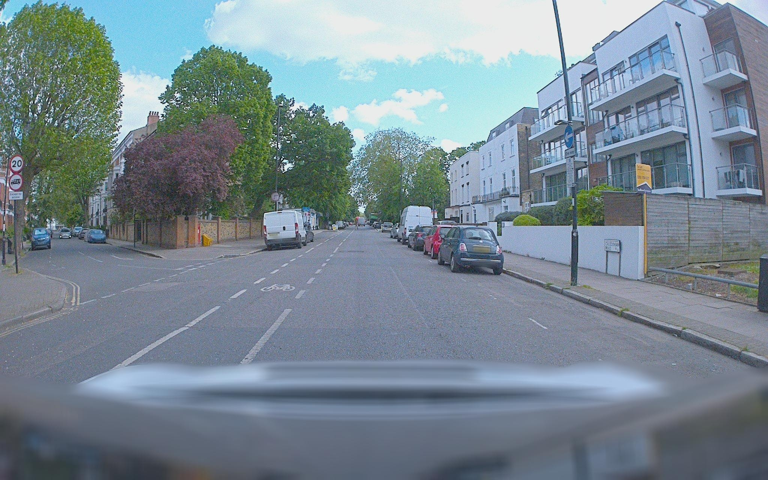

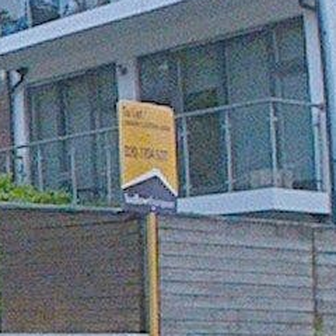

In [16]:
IM = lambda im: {"type": "image", "image": im}      # one image piece of a chat message
TX = lambda t: {"type": "text", "text": t}          # one text piece of a chat message

def frame(d, seg, i):                                # frames 0-3 at 512 px, the last frame at 768 px
    im = Image.open(f"{d}/{seg}/{i}.jpg").convert("RGB"); im.thumbnail((512, 512) if i < 4 else (768, 768)); return im

def crop_full(d, seg, cx, cy, wc, hc, out):          # cut a window from the FULL-resolution last frame, centred on (cx, cy)
    img = Image.open(f"{d}/{seg}/4.jpg").convert("RGB"); W, H = img.size; wc, hc = min(wc, W), min(hc, H)
    x0 = int(min(max(cx - wc / 2, 0), W - wc)); y0 = int(min(max(cy - hc / 2, 0), H - hc))
    return img.crop((x0, y0, x0 + wc, y0 + hc)).resize(out, Image.LANCZOS)

def light_crops(d, seg):                             # LIGHT_ZOOM: up to 2 crops around the traffic-light candidates
    out = []
    for c in REC[seg].get("lights", [])[:2]:
        x0, y0, x1, y1 = c["box"]; side = max(240, 7 * max(x1 - x0, y1 - y0))
        out.append(crop_full(d, seg, (x0 + x1) / 2, (y0 + y1) / 2, side, side, (336, 336)))
    return out

def far_crop(d, seg):                                # FAR_ZOOM: a crop around the vanishing point = the road far ahead
    vp = REC[seg].get("vp")
    return crop_full(d, seg, vp[0], vp[1], 960, 540, (448, 252)) if vp else None

PREAMBLE = "5 frames from your car's front camera, 1 second apart, oldest first. The last frame is now."
STYLE = "You are the driver. Answer with one short sentence, no preamble."
CUE_SET = ["TIME", "EGO", "LIGHT_ZOOM", "FAR_ZOOM"]
FLIP = {"stopped": "speeding up", "speeding up": "stopped", "slowing down": "speeding up"}   # for the wrong-cue test

def build(row, use, wrong_ego=False):
    """Builds ONE example's input.
    use = the cues allowed for this example (empty set = no cues at all).
    A cue is attached only if (1) it is in `use`, (2) the tagger routes it to this question type, (3) it exists for this clip.
    Returns (system text or None, user content list, names of the cues actually attached)."""
    d, seg = DIRS[row.split], row.segment_id; r = REC[seg]; routed = set(row.cues); given = []
    if WHY_GETS_ZOOMS and int(row.cls) in (1, 2): routed |= {"LIGHT_ZOOM", "FAR_ZOOM"}
    c = []
    # ---- cue 1, TIME: a text label before every frame (goes to every question)
    if "TIME" in use:
        c.append(TX(PREAMBLE)); given.append("TIME")
        for i in range(5): c += [TX(f"t = {i - 4} s" + (" (now)" if i == 4 else "") + ":"), IM(frame(d, seg, i))]
    else:
        c += [IM(frame(d, seg, i)) for i in range(5)]
    # ---- cue 2, LIGHT_ZOOM: extra images after the frames
    if "LIGHT_ZOOM" in use and "LIGHT_ZOOM" in routed and r.get("lights"):
        for im in light_crops(d, seg): c += [TX("Zoomed view of a possible traffic light in the last frame:"), IM(im)]
        given.append("LIGHT_ZOOM")
    # ---- cue 3, FAR_ZOOM: one extra image (skipped when a light zoom was already given)
    if "FAR_ZOOM" in use and "FAR_ZOOM" in routed and "LIGHT_ZOOM" not in given:
        im = far_crop(d, seg)
        if im is not None: c += [TX("Zoomed view of the road far ahead in the last frame:"), IM(im)]; given.append("FAR_ZOOM")
    # ---- cue 4, EGO: one plain sentence in the SYSTEM prompt (why / decision / own-action questions)
    sysm = None
    if "EGO" in use and "EGO_DETAIL" in routed and r.get("state"):
        state = FLIP.get(r["state"], r["state"]) if wrong_ego else r["state"]
        sysm = f"{STYLE}\nRight now your car is {state}."; given.append("EGO")
    return sysm, c, given

INSTR = "Answer in one short sentence."
def to_messages(sysm, content, question, answer=None):
    m = ([{"role": "system", "content": [TX(sysm)]}] if sysm else []) + [{"role": "user", "content": content + [TX(f"{question}\n{INSTR}")]}]
    if answer is not None: m.append({"role": "assistant", "content": [TX(" ".join(str(answer).split()))]})
    return m

# ---- look at one real example with every cue switched on
ex = next(r for r in POOL.itertuples() if r.cls in (1, 2) and REC[r.segment_id].get("state") and REC[r.segment_id].get("lights"))
sysm, content, given = build(ex, set(CUE_SET))
print("cues attached:", given, "\n\nSYSTEM:", sysm, "\n\nUSER:")
for piece in content: print("  ", piece["text"] if piece["type"] == "text" else f"[image {piece['image'].size}]")
print("  ", ex.question, "/", INSTR, "\n\nANSWER TO LEARN:", ex.answer)
for piece in content[-4:]:
    if piece["type"] == "image": display(piece["image"])

In [17]:
from unsloth import FastVisionModel, is_bf16_supported
from unsloth.trainer import UnslothVisionDataCollator
MID = "unsloth/Qwen3.5-2B"
model, processor = FastVisionModel.from_pretrained(MID, load_in_4bit=True, use_gradient_checkpointing="unsloth")
model = FastVisionModel.get_peft_model(model, finetune_vision_layers=False, finetune_language_layers=True,
                                       finetune_attention_modules=True, finetune_mlp_modules=True,
                                       r=16, lora_alpha=32, lora_dropout=0.0, bias="none", random_state=3407)
model.print_trainable_parameters()
TOK = processor.tokenizer

# from unsloth import FastVisionModel, is_bf16_supported
# from unsloth.trainer import UnslothVisionDataCollator
# MID = "unsloth/Qwen3.5-2B"
# model, processor = FastVisionModel.from_pretrained(MID, load_in_4bit=True, use_gradient_checkpointing="unsloth")
# model = FastVision.get_peft_model(model, fine_tune_vision_layers= False, fine_tune_language_layers = True,
#                                  finetune_attention_modules=True, fine_tune_mlp_modules=True,
#                                  r=16,lora_alpha=32, lora_dropout=0.0, bias="none", random_state=3407)
# model.print_trainable_parameters()
# TOK = processor.tokenizer

==((====))==  Unsloth 2026.11.4: Fast Qwen3_5 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.
Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


model.safetensors.index.json:   0%|          | 0.00/64.5k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Loading weights:   0%|          | 0/617 [00:00<?, ?it/s]

Unsloth: the model has bfloat16 layers on GPU 0 (Tesla T4), which has no native bfloat16, so they run slowly. Load with dtype = torch.float16, or keep the model on bfloat16 GPUs with CUDA_VISIBLE_DEVICES.
trainable params: 16,819,200 || all params: 2,230,060,864 || trainable%: 0.7542


In [18]:
import datasets
# ---- cue dropout: decided ONCE per training example with a fixed seed (reproducible).
#      Each of the 4 cues survives with probability 75 %, independently of the others.
rng = random.Random(123)
USE = [{c for c in CUE_SET if rng.random() >= P_DROP} for _ in range(len(POOL))]
print("cues allowed for the first 5 examples:", USE[:5])

GIVEN = collections.Counter()                          # counts the cues that really got attached during training
def _build(batch):                                     # called by the trainer whenever it needs examples -> images are built lazily
    out = []
    for i in batch["idx"]:
        row = next(POOL.iloc[[i]].itertuples()); sysm, content, g = build(row, USE[i]); GIVEN.update(g)
        out.append(to_messages(sysm, content, row.question, row.answer))
    return {"messages": out}
TRAIN_DS = datasets.Dataset.from_dict({"idx": list(range(len(POOL)))}).with_transform(_build)

# data collator packs everything into tensors and masks everything except the answer
collator = UnslothVisionDataCollator(model, processor, train_on_responses_only=True,
                                     instruction_part="<|im_start|>user\n", response_part="<|im_start|>assistant\n")
b = collator([TRAIN_DS[0]]); lab = b["labels"][0]
log("tokens in example 1:", len(lab), "| graded tokens:", int((lab != -100).sum()), "| graded text:", repr(TOK.decode(lab[lab != -100])))
GIVEN.clear()

cues allowed for the first 5 examples: [{'LIGHT_ZOOM'}, {'FAR_ZOOM', 'TIME', 'LIGHT_ZOOM'}, {'FAR_ZOOM', 'TIME', 'LIGHT_ZOOM'}, {'LIGHT_ZOOM'}, {'FAR_ZOOM', 'TIME', 'LIGHT_ZOOM'}]
Unsloth: Model does not have a default image size - using 512
[ 0.47h] tokens in example 1: 975 | graded tokens: 25 | graded text: '<think>\n\n</think>\n\nI am steering right in this situation to keep a safe distance from the cycle lane on the left.<|im_end|>'


In [ ]:
from trl import SFTTrainer, SFTConfig
# • SFTTrainer: A specialized trainer class that simplifies Supervised Fine-Tuning (SFT). It automatically manages data formatting, tokenization, sequence packing, and aligning special/EOS tokens so you do not have to write custom training loops from scratch.
# • SFTConfig: A configuration data class used to set training hyperparameters and SFT-specific options (such as batch size, learning rate, output directory, maximum sequence length, and completion-only loss settings), which you pass into the SFTTrainer.
import transformers
FastVisionModel.for_training(model)
args = SFTConfig(per_device_train_batch_size=1, gradient_accumulation_steps=8,    # 8 examples per update
                 num_train_epochs=1, warmup_steps=10, learning_rate=2e-4, lr_scheduler_type="linear",
                 optim="adamw_8bit", weight_decay=0.01,
                 fp16=not is_bf16_supported(), bf16=is_bf16_supported(), logging_steps=25, seed=3407,
                 output_dir=f"{WORK}/ckpt_{MODE}", save_strategy="no", report_to="none",
                 remove_unused_columns=False, dataset_text_field="", dataset_kwargs={"skip_prepare_dataset": True},
                 max_length=4096, dataloader_num_workers=0)
class Progress(transformers.TrainerCallback):
    def on_log(self, a, state, control, logs=None, **kw):
        log(f"update {state.global_step}/{state.max_steps} | {logs} | cues so far {dict(GIVEN)}")
        if hours() > TRAIN_DEADLINE_H: log("TIME GUARD: stopping early"); control.should_training_stop = True
trainer = SFTTrainer(model=model, tokenizer=processor, data_collator=collator, train_dataset=TRAIN_DS, args=args, callbacks=[Progress()])
t0 = time.time(); trainer.train()
losses = [h["loss"] for h in trainer.state.log_history if "loss" in h]
TSTAT = {"mode": MODE, "updates": trainer.state.global_step, "of": trainer.state.max_steps, "minutes": round((time.time() - t0) / 60, 1),
         "loss_first": losses[:1], "loss_last": losses[-1:], "cues_given_in_training": dict(GIVEN)}
log("FINE-TUNED", TSTAT)
model.save_pretrained(f"{WORK}/lora_{MODE}"); processor.save_pretrained(f"{WORK}/lora_{MODE}")

In [ ]:
FastVisionModel.for_inference(model)
END_IDS = [i for i in {TOK.convert_tokens_to_ids("<|im_end|>"), TOK.eos_token_id} if isinstance(i, int) and i >= 0]
@torch.inference_mode()
def answer(sysm, content, question):
    x = processor.apply_chat_template(to_messages(sysm, content, question), add_generation_prompt=True, tokenize=True,
                                      return_dict=True, return_tensors="pt").to("cuda")
    o = model.generate(**x, max_new_tokens=48, do_sample=False, use_cache=True, eos_token_id=END_IDS)
    raw = TOK.decode(o[0][x["input_ids"].shape[1]:], skip_special_tokens=True)
    return re.split(r"<\|im_|\n", re.sub(r"<think>.*?</think>", "", raw, flags=re.S).strip())[0].strip()

# three tests of the SAME fine-tuned model:
#   ft_cues           all cues on                          -> the main result
#   ft_cues_nocue     all cues off                         -> does the score drop without cues?
#   ft_cues_wrongego  all cues on, car-state sentence FLIPPED (stopped <-> speeding up) -> does the model really read the sentence?
TESTS = [("ft_cues", set(CUE_SET), False), ("ft_cues_nocue", set(), False), ("ft_cues_wrongego", set(CUE_SET), True)]
DONE = {}
for name, use, wrong in TESTS:
    rows = []
    for k, r in enumerate(items.itertuples()):
        try:
            sysm, content, g = build(r, use, wrong_ego=wrong)
            if wrong and "EGO" not in g: a = DONE["ft_cues"][k]            # no ego sentence -> identical input to ft_cues
            else: a = answer(sysm, content, r.question)
        except Exception as e:
            a, g = f"__ERROR__ {e!r}"[:150], ["error"]
        rows.append([r.question_id, r.set, r.segment_id, r.cls, r.cname, "|".join(g), a])
        if k % 250 == 0: log(f"{name} {k}/{len(items)} | {a[:70]!r}")
    DONE[name] = [x[-1] for x in rows]
    pd.DataFrame(rows, columns=["question_id", "set", "segment_id", "cls", "cname", "cues_given", "answer"]).to_csv(f"{OUT}/preds_{name}.csv", index=False)
    log("SAVED", name)
del model, trainer; gc.collect(); torch.cuda.empty_cache()

In [ ]:
from transformers import pipeline
from math import comb
judge = pipeline("text-classification", model="wayveai/Lingo-Judge", device=0)
REFS = pd.concat([ev[["question_id", "question", "answer"]].assign(set="eval"), dev[["question_id", "question", "answer"]].assign(set="dev")])
def mcnemar(a, b):                                    # paired test: same questions answered two ways
    win, loss = int(((b == 1) & (a == 0)).sum()), int(((a == 1) & (b == 0)).sum()); n = win + loss
    p = 1.0 if n == 0 else min(1.0, 2 * sum(comb(n, i) for i in range(min(win, loss) + 1)) / 2.0 ** n)
    return f"{100 * (b.mean() - a.mean()):+.1f} (helped {win}, hurt {loss}, p={p:.4f})"
S = {}; L = [f"# Notebook B: fine-tuning WITH cues, {hours():.1f} h", f"fine-tuning: {TSTAT}", f"cue estimator gates: {CUES['gates']}", ""]
for name, _, _ in TESTS:
    p = pd.read_csv(f"{OUT}/preds_{name}.csv", dtype={"question_id": str}); p["answer"] = p["answer"].fillna("").astype(str)
    rf = REFS.merge(p[["question_id", "set", "answer"]].rename(columns={"answer": "pred"}), on=["question_id", "set"])
    texts = [f"[CLS]\nQuestion: {q}\nAnswer: {str(a).lower().strip()}\nStudent: {s.lower().strip()}" for q, a, s in zip(rf["question"], rf["answer"], rf["pred"])]
    rf["score"] = [o["score"] for o in judge(texts, batch_size=32, truncation=True, max_length=128)]
    g = rf.groupby(["question_id", "set"])["score"]
    p = p.set_index(["question_id", "set"])
    p["correct"] = (g.max().reindex(p.index).fillna(0) > 0.5).astype(int)            # best of the human answers (official has 2, dev has 1)
    p["correct_1ref"] = (g.first().reindex(p.index).fillna(0) > 0.5).astype(int)     # only the FIRST human answer
    p["words"] = p["answer"].str.split().str.len(); p.reset_index().to_csv(f"{OUT}/scored_{name}.csv", index=False); S[name] = p
    L.append(f"{name}: official {100 * p.xs('eval', level=1)['correct'].mean():.1f} (with 1 reference only: {100 * p.xs('eval', level=1)['correct_1ref'].mean():.1f})"
             f" | dev {100 * p.xs('dev', level=1)['correct'].mean():.1f} | words {p['words'].mean():.1f} | errors {int(p['answer'].str.startswith('__ERROR__').sum())}")
L += ["", "(for comparison: zero-shot official 64.0 / dev 36.0; plain fine-tuning official 62.6 / dev 59.0)", ""]
C, N, W = S["ft_cues"], S["ft_cues_nocue"], S["ft_cues_wrongego"]
L.append("cues ON vs cues OFF, all 1000: " + mcnemar(N["correct"].values, C["correct"].values))
ego = C["cues_given"].fillna("").str.contains("EGO").values
L.append(f"right vs WRONG car-state sentence, the {int(ego.sum())} questions that got one: " + mcnemar(W["correct"].values[ego], C["correct"].values[ego]))
L.append("\nper question type (cues ON accuracy, and change vs cues OFF):")
for cn in C["cname"].value_counts().index:
    m = (C["cname"] == cn).values
    L.append(f"  {cn:14s} n={int(m.sum()):3d}  {100 * C['correct'].values[m].mean():.1f}  " + mcnemar(N["correct"].values[m], C["correct"].values[m]))
rep = "\n".join(L); open(f"{OUT}/REPORT.md", "w").write(rep); print(rep)
with tarfile.open(f"{WORK}/ft_cues_results.tar", "w") as tf:
    for f in glob.glob(f"{OUT}/*"): tf.add(f, arcname=f"ft_cues/{os.path.basename(f)}")
log("ALL DONE -> /kaggle/working/ft_cues_results.tar")